# **Student_Mark_Predicter**

---



Project Level : Beginner,
Learning Mode : Theory + Google Colab Practical,
Algorithm : Multiple Linear Regression,
Input Feature : Study hours, Attendance,
Target Variable : Expected Marks,
Primary Tools : Python,Pandas,Matplotlib,Scikit-learn;

---







In [ ]:
#step 1
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

print("Libraries imported successfully")

Libraries imported successfully


Create **Database**

In [ ]:
#step 2
data = {
    "Study_Hours" : [1,2,3,4,5,6,7,8,9,10],
    "Attendance" : [50,55,60,65,70,72,78,82,88,90],
    "Marks" : [35,40,45,52,58,65,70,78,85,90]
}

df = pd.DataFrame(data)

print(df)

   Study_Hours  Attendance  Marks
0            1          50     35
1            2          55     40
2            3          60     45
3            4          65     52
4            5          70     58
5            6          72     65
6            7          78     70
7            8          82     78
8            9          88     85
9           10          90     90


Inspect the **Dataset**

In [ ]:
#step 3
print("First five rows:")
print(df.head())

print("Last five rows:")
print(df.tail())

print("\n Dataset shape :")
print(df.shape)

print("\n Column names:")
print(df.columns)

print("\n Number of Rows:")
print(df.shape[0])

print("\n Number of columns:")
print(df.shape[1])

print("\nDataset Description or summary:")
print(df.describe())

print("\nDataset Information:")
print(df.info())

First five rows:
   Study_Hours  Attendance  Marks
0            1          50     35
1            2          55     40
2            3          60     45
3            4          65     52
4            5          70     58
Last five rows:
   Study_Hours  Attendance  Marks
5            6          72     65
6            7          78     70
7            8          82     78
8            9          88     85
9           10          90     90

 Dtaset shape :
(10, 3)

 Column names:
Index(['Study_Hours', 'Attendance', 'Marks'], dtype='object')

 Number of Rows:
10

 Number of columns:
3

Dataset Description or summary:
       Study_Hours  Attendance      Marks
count     10.00000   10.000000  10.000000
mean       5.50000   71.000000  61.800000
std        3.02765   13.646326  19.030969
min        1.00000   50.000000  35.000000
25%        3.25000   61.250000  46.750000
50%        5.50000   71.000000  61.500000
75%        7.75000   81.000000  76.000000
max       10.00000   90.000000  90.000000



Check Data **quality**

In [ ]:
#step 4
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
Study_Hours    0
Attendance     0
Marks          0
dtype: int64

Duplicate rows:
0


Data **Visualisation**

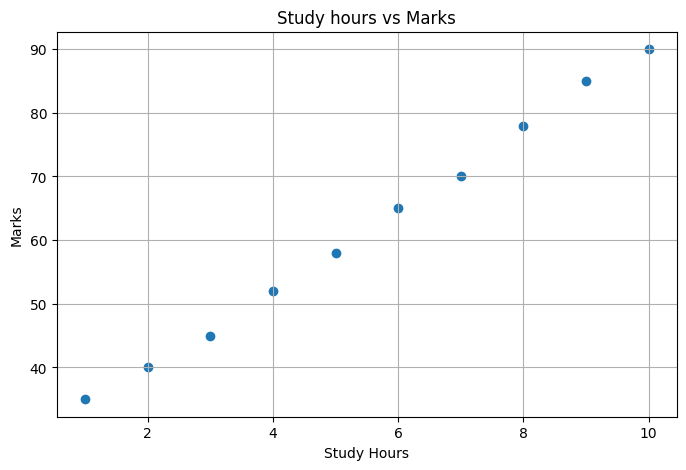

In [ ]:
#step 5
plt.figure(figsize=(8,5))
plt.scatter(df["Study_Hours"],df["Marks"])
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Study hours vs Marks")
plt.grid(True)
plt.show()

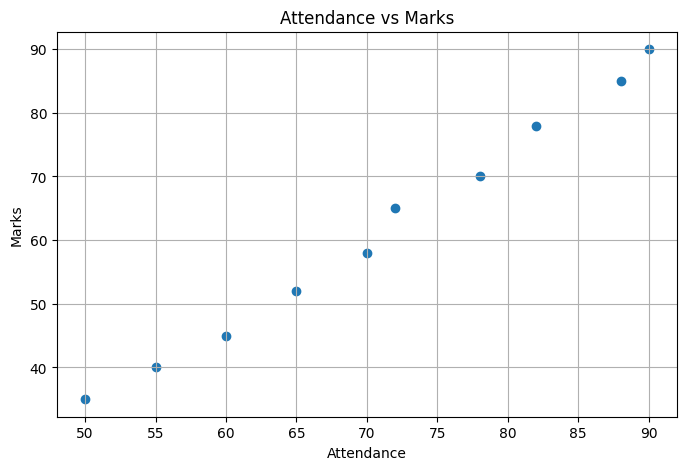

In [ ]:
#step 6
plt.figure(figsize=(8,5))
plt.scatter(df["Attendance"],df["Marks"])
plt.xlabel("Attendance")
plt.ylabel("Marks")
plt.title("Attendance vs Marks")
plt.grid(True)
plt.show()

# **Prepring Data for Machine Learning**

Separate featurs and **target**

In [ ]:
x = df[["Study_Hours","Attendance"]]
y = df["Marks"]

print("features (x):")
print(x)

print("Target (y):")
print(y)

features (x):
   Study_Hours  Attendance
0            1          50
1            2          55
2            3          60
3            4          65
4            5          70
5            6          72
6            7          78
7            8          82
8            9          88
9           10          90
Target (y):
0    35
1    40
2    45
3    52
4    58
5    65
6    70
7    78
8    85
9    90
Name: Marks, dtype: int64


In [ ]:
# Train test Split
x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42)

print("Training Samples:", len(x_train))

print("Testing Samples:", len(x_test))

Training Samples: 8
Testing Samples: 2


In [ ]:
#Create the model
model = LinearRegression()

In [ ]:
#Train the model
model.fit(x_train,y_train)

LinearRegression()

In [ ]:
#Inspect learned parameters
print("Coefficients:")
print(model.coef_)

print("Intercept:")
print(model.intercept_)

Coefficients:
[ 9.04589372 -0.64251208]
Intercept:
57.410628019323504


In [ ]:
#Predict the test data
y_pred=model.predict(x_test)

print("Actual values:")
print(y_test.values)

print("Predicted values:")
print(y_pred)

Actual values:
[85 40]
Predicted values:
[82.2826087  40.16425121]


In [ ]:
#Compare Actual and predicted values
comparison_df = pd.DataFrame({
    "Actual":y_test,
   "Predicted":y_pred
    })
print(comparison_df)

   Actual  Predicted
8      85  82.282609
1      40  40.164251


In [ ]:
#Mean Absolute error
mae = mean_absolute_error(y_test,y_pred)
print("Mean Absolute Error:",mae)

Mean Absolute Error: 1.4408212560386389


In [ ]:
#Mean Squared error
mse = mean_squared_error(y_test,y_pred)
print("Mean Squared Error:",mse)

Mean Squared Error: 3.70559698009285


In [ ]:
#Root Mean Squared Error
rmse = np.sqrt(mse)
print("Root Mean Squared Error:",rmse)

Root Mean Squared Error: 1.924992722088281


In [ ]:
#R2 Score
r2=r2_score(y_test,y_pred)
print("R2 Score:",r2)
#

R2 Score: 0.992680302261545


In [ ]:
#predict marks for a new student
new_student = pd.DataFrame({
    "Study_Hours" : [6.5],
    "Attendance" : [95]
})

predicted_marks = model.predict(new_student)

print("Study hours:",new_student["Study_Hours"].values[0])
print("Attendance:",new_student["Attendance"].values[0])
print("Predicted Marks:",predicted_marks[0],2)

Study hours: 6.5
Attendance: 95
Predicted Marks: 55.170289855072525 2


In [ ]:
import joblib
import sklearn

# Save the trained model
joblib.dump(model,"student_marks_model.pkl")

# Check the installed scikit-learn version
print("Scikit-learn version:",sklearn.__version__)

print("Model saved successfully")


Scikit-learn version: 1.6.1
Model saved successfully


In [ ]:
from google.colab import files

# Download the trained model
files.download("student_marks_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>